# Uniform Distribution

In [37]:
from sklearn.decomposition import PCA
from umap import UMAP
import numpy as np
import matplotlib.pyplot as plt

from src.ExistingAlgorithms import area, sklearn_available
from src.GaussianMixture import gaussian_mixture
from src.NoiseUtils import plot_clusters, assign_labels

SKIP = 10
PATH_RESULTS = 'src/Results_Noise_New'
PATH_DATA = '/home/jcep-nu/Documents/nicolasdc/Datasets/Squeezer/pump_2.0dB_rawTraces_Noise_30042025.npy'

In [38]:
def g2(n):

   var_ = np.var(n)
   mean_ = np.mean(n)

   return 1 + (var_ - mean_) / mean_**2

## Data

In [39]:
data_train = np.load(PATH_DATA)
data_detect0 = data_train[0].T
# data_detect0 = (data_detect0 - np.mean(data_detect0)) / np.std(data_detect0)
data_detect0 = (data_detect0 - np.min(data_detect0)) / np.ptp(data_detect0)
data_detect1 = data_train[1].T
# data_detect1 = (data_detect1 - np.mean(data_detect1)) / np.std(data_detect1)
data_detect1 = (data_detect1 - np.min(data_detect1)) / np.ptp(data_detect1)

In [40]:
data_detect0.shape

(1000000, 100)

## Methods

### Area

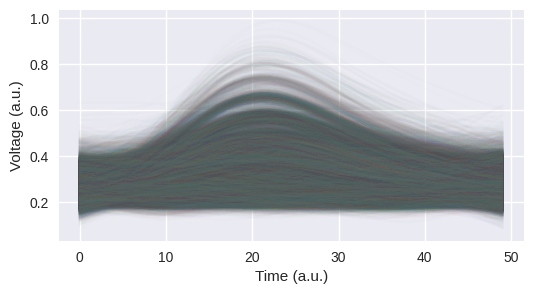

In [5]:
X_l_AREA0  = area(data_detect0[:,:50], filtering = True, plot_filter = True, threshold = 0.03, critical_frequency = 0.08)

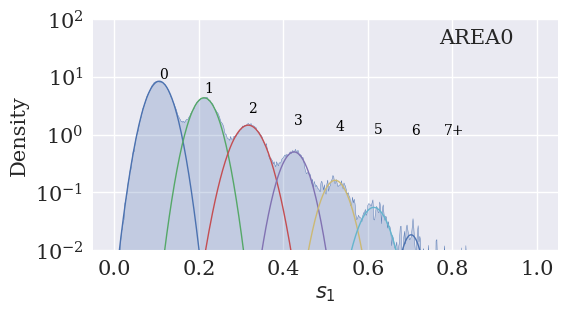

In [6]:
name_method = 'AREA0'
gm0 = gaussian_mixture(
   X_l_AREA0[::10],
   data_detect0[::10],
   means_init = np.array(
      [[0.11815943],
       [0.21203894],
       [0.29386814],
       [0.45183543],
       [0.52515359],
       [0.61117338],
       [0.7459916 ],
       [0.7659916 ]]),
   number_cluster = 8,
   tol = 1e-4,
   cluster_iter = 10,
   width_plot=6,
   height_plot=3
)

gm0.plot_density(
   bw_adjust = 0.1, 
   plot_gaussians = True,
   text = name_method,
   save_path = PATH_RESULTS
)

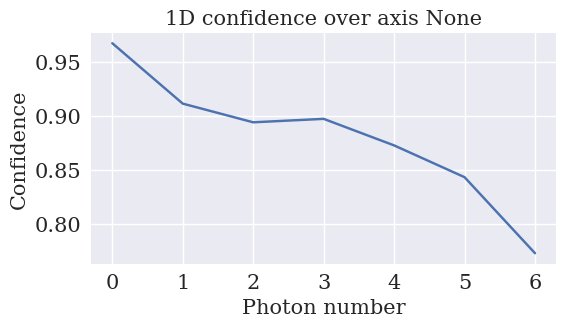

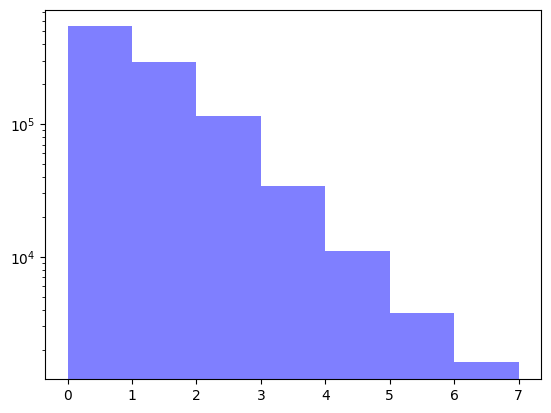

In [7]:
gm0.plot_confidence_1d(expected_prob=None)

n_detect0 = gm0.predict(X_l_AREA0)

plt.hist(
   n_detect0,
   bins=np.unique(n_detect0),
   color='blue',
   alpha=0.5,
   label='n_detect0'
)
plt.yscale('log')
plt.show()

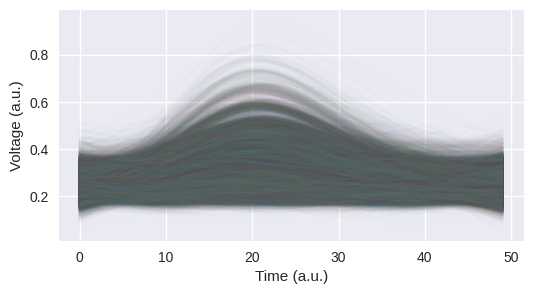

In [8]:
X_l_AREA1  = area(data_detect1[:,:50], filtering = True, plot_filter = True, threshold = 0.03, critical_frequency = 0.08)

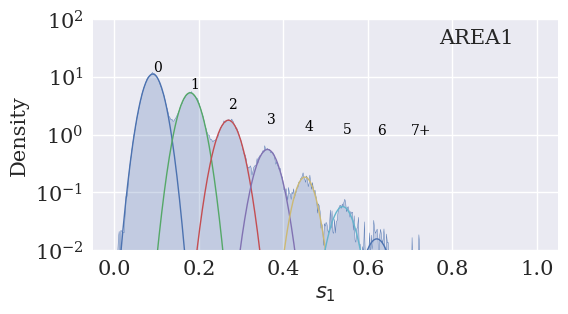

In [9]:
name_method = 'AREA1'
gm1 = gaussian_mixture(
   X_l_AREA1[::10],
   data_detect1[::10],
   means_init = np.array(
      [[0.11815943],
       [0.21203894],
       [0.29386814],
       [0.43183543],
       [0.47183543],
       [0.52515359],
       [0.61117338],
       [0.7459916 ]]),
   number_cluster = 8,
   tol = 1e-4,
   cluster_iter = 10,
   width_plot=6,
   height_plot=3
)

gm1.plot_density(
   bw_adjust = 0.1, 
   plot_gaussians = True,
   text = name_method,
   save_path = PATH_RESULTS
)

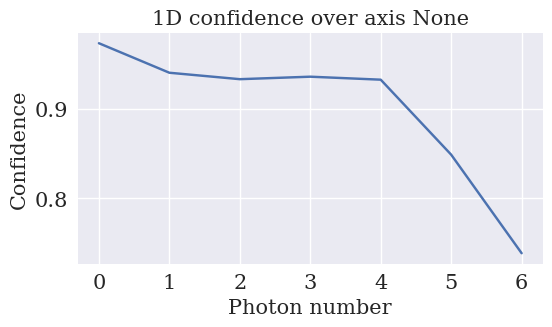

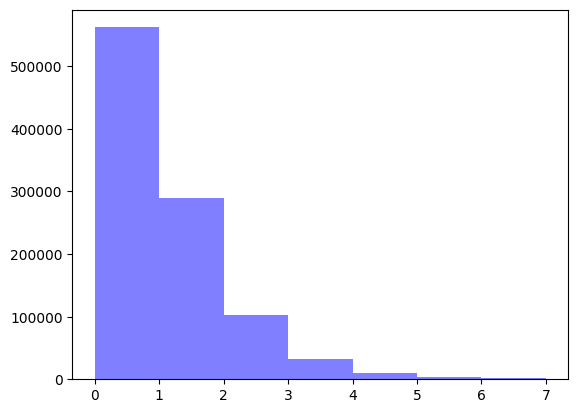

In [10]:
gm1.plot_confidence_1d(expected_prob=None)

n_detect1 = gm1.predict(X_l_AREA1)

plt.hist(
   n_detect1,
   bins=np.unique(n_detect1),
   color='blue',
   alpha=0.5,
   label='n_detect1'
)
plt.show()

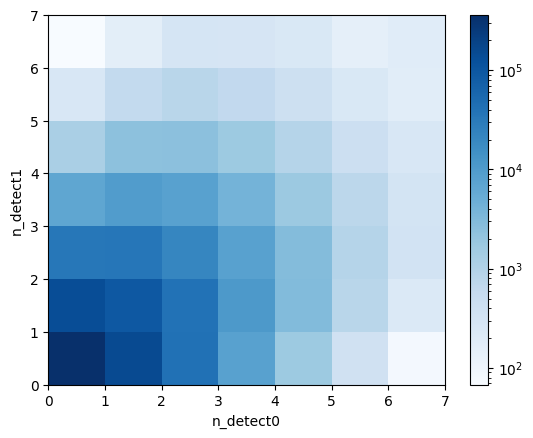

G2 (detector 0) :  1.4316659619383085
G2 (detector 1) :  1.4599146168153796


In [11]:
plt.hist2d(
   n_detect0,
   n_detect1,
   bins=np.unique(n_detect0),
   cmap='Blues',
   cmin=0,
   norm='log'
)
plt.colorbar()
plt.xlabel('n_detect0')
plt.ylabel('n_detect1')
plt.show()

print('G2 (detector 0) : ',g2(n_detect0))
print('G2 (detector 1) : ',g2(n_detect1))

In [12]:
H_area, xedges, yedges = np.histogram2d(
   n_detect0,
   n_detect1,
   bins=np.unique(n_detect0),
   density=True
)

### PCA

In [13]:
X_l_PCA0 = PCA(n_components=1).fit_transform(data_detect0[:,:50])

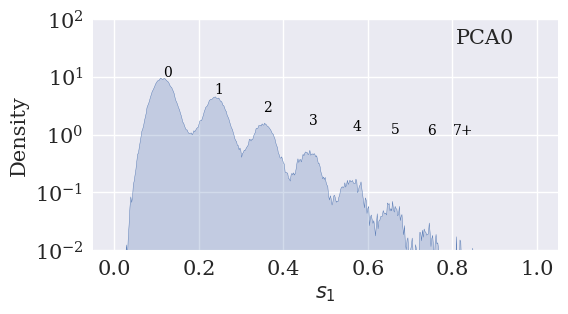

In [14]:
name_method = 'PCA0'
gm0 = gaussian_mixture(
   X_l_PCA0[::10],
   data_detect0[::10],
   means_init = np.array(
      [[0.11815943],
       [0.21203894],
       [0.37544908],
       [0.52515359],
       [0.61117338],
       [0.65117338],
       [0.7459916 ],
       [0.7659916 ]]),
   number_cluster = 8,
   tol = 1e-4,
   cluster_iter = 10,
   width_plot=6,
   height_plot=3
)

gm0.plot_density(
   bw_adjust = 0.1, 
   plot_gaussians = False,
   text = name_method,
   save_path = PATH_RESULTS
)

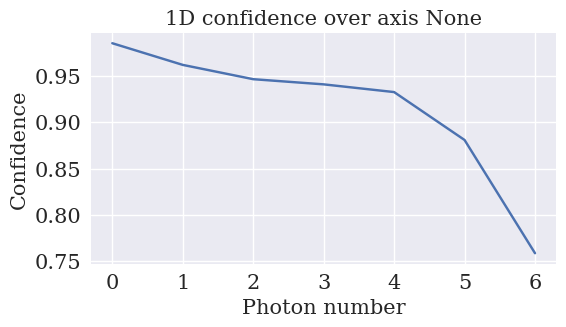

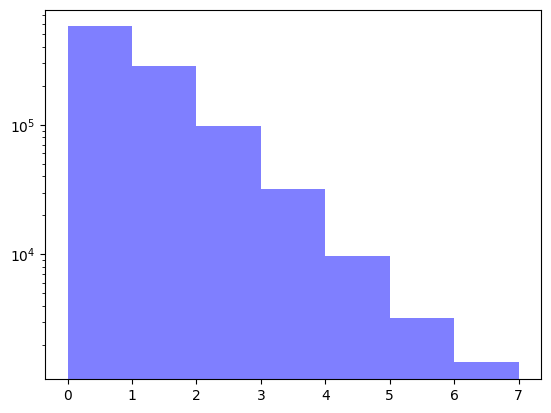

In [15]:
gm0.plot_confidence_1d(expected_prob=None)

n_detect0 = gm0.predict(X_l_PCA0)

plt.hist(
   n_detect0,
   bins=np.unique(n_detect0),
   color='blue',
   alpha=0.5,
   label='n_detect0'
)
plt.yscale('log')
plt.show()

In [16]:
X_l_PCA1 = PCA(n_components=1).fit_transform(data_detect1[:,:50])

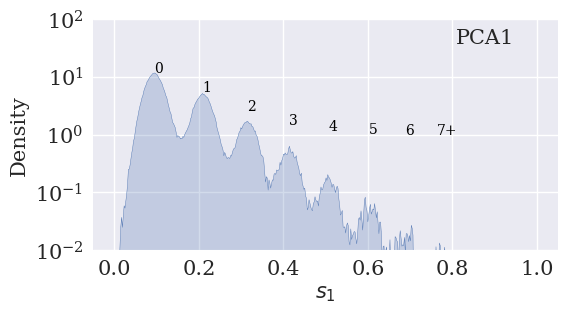

In [17]:
name_method = 'PCA1'
gm1 = gaussian_mixture(
   X_l_PCA1[::10],
   data_detect1[::10],
   means_init = np.array(
      [[0.11815943],
       [0.21386814],
       [0.29386814],
       [0.4544908],
       [0.50515359],
       [0.65117338],
       [0.70117338],
       [0.7459916 ]]),
   number_cluster = 8,
   tol = 1e-4,
   cluster_iter = 10,
   width_plot=6,
   height_plot=3
)

gm1.plot_density(
   bw_adjust = 0.1, 
   plot_gaussians = False,
   text = name_method,
   save_path = PATH_RESULTS
)

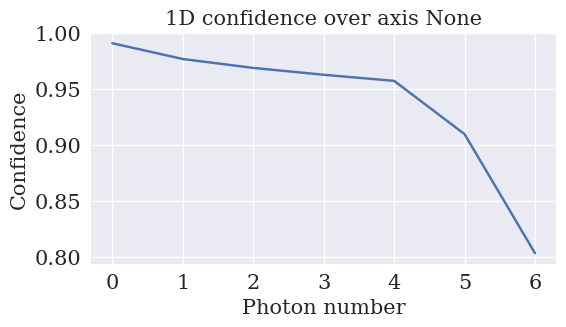

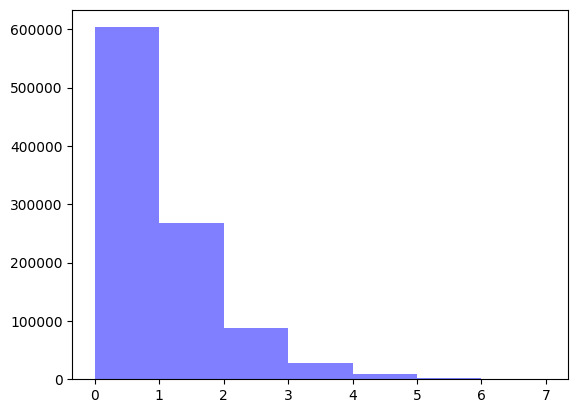

In [18]:
gm1.plot_confidence_1d(expected_prob=None)

n_detect1 = gm1.predict(X_l_PCA1)

plt.hist(
   n_detect1,
   bins=np.unique(n_detect1),
   color='blue',
   alpha=0.5,
   label='n_detect1'
)
plt.show()

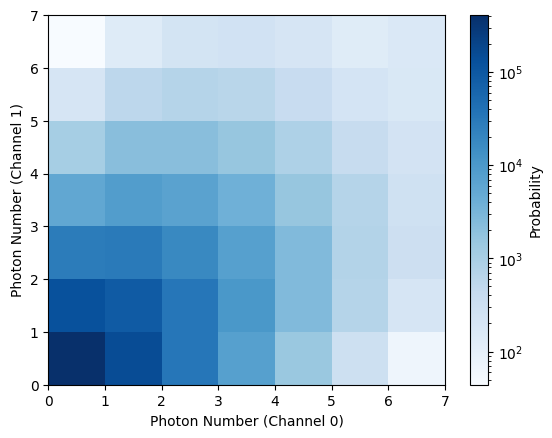

G2 (detector 0) :  1.5142767182373555
G2 (detector 1) :  1.5922296438737122


In [19]:
plt.hist2d(
   n_detect0,
   n_detect1,
   bins=np.unique(n_detect0),
   cmap='Blues',
   cmin=0,
   norm='log'
)
plt.colorbar(label='Probability')
plt.xlabel('Photon Number (Channel 0)')
plt.ylabel('Photon Number (Channel 1)')
plt.savefig('NoiseDist.pdf')
plt.show()

print('G2 (detector 0) : ',g2(n_detect0))
print('G2 (detector 1) : ',g2(n_detect1))

In [20]:
H_pca, xedges, yedges = np.histogram2d(
   n_detect0,
   n_detect1,
   bins=np.unique(n_detect0),
   density=True)

## PCA 2D

In [21]:
X_l_PCA0 = PCA(n_components=2).fit_transform(data_detect0[:,:50])

/home/jcep-nu/miniconda3/envs/ML/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: Log scale: values of z <= 0 have been masked
  cset = contour_func(


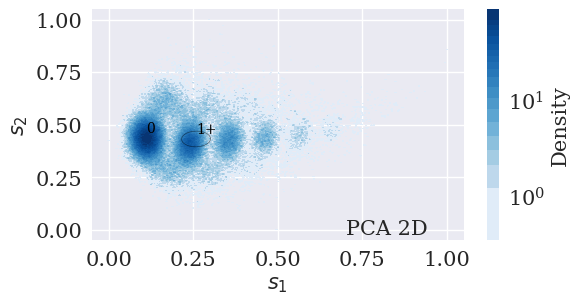

In [22]:
name_method = 'PCA 2D'
gm0 = gaussian_mixture(
   X_l_PCA0[::10],
   data_detect0[::10],
   means_init = None,
   number_cluster = 2,
   tol = 1e-6,
   cluster_iter = 1,
   width_plot=6,
   height_plot=3
)

gm0.plot_density(
   bw_adjust = 0.1, 
   plot_gaussians = True,
   text = name_method,
   save_path = PATH_RESULTS
)

## UMAP

In [41]:
X_l_UMAP0 = sklearn_available(data_detect0[:,:50], data_detect0[:,:50], PATH_RESULTS, UMAP, 'detect0[:,:50]_500_2c_Noise_2dB.npy',n_components=2, n_neighbors=500)

In [ ]:
classes0 = assign_labels(X_l_UMAP0, data_detect0[:,:50], SKIP+20, eps=0.000001, min_cluster_size=20)
np.unique(classes0)

/home/jcep-nu/miniconda3/envs/ML/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/jcep-nu/miniconda3/envs/ML/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


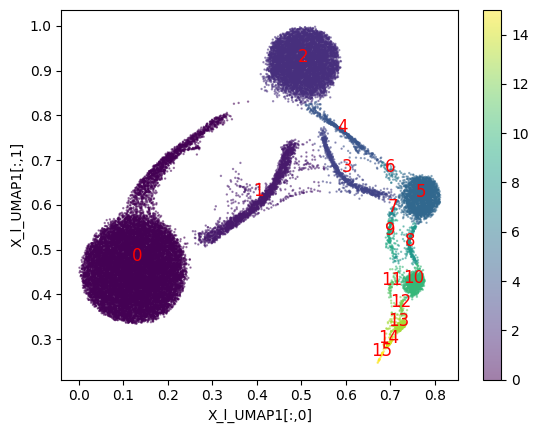

3.199712485794333

In [ ]:
plot_clusters(X_l_UMAP0, classes0, SKIP+20)
g2(classes0)

/home/jcep-nu/miniconda3/envs/ML/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: Log scale: values of z <= 0 have been masked
  cset = contour_func(


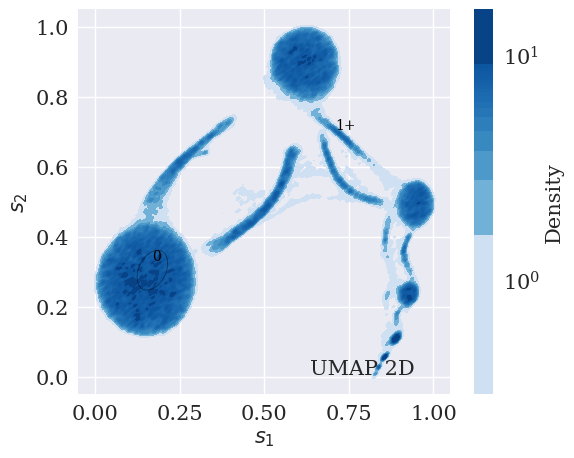

In [26]:
name_method = 'UMAP 2D'
gm0 = gaussian_mixture(
   X_l_UMAP0[::10],
   data_detect0[::10],
   means_init = None,
   number_cluster = 2,
   tol = 1e-1,
   cluster_iter = 1,
   width_plot=6,
   height_plot=5
)

gm0.plot_density(
   bw_adjust = 0.1, 
   plot_gaussians = True,
   text = name_method,
   save_path = PATH_RESULTS
)

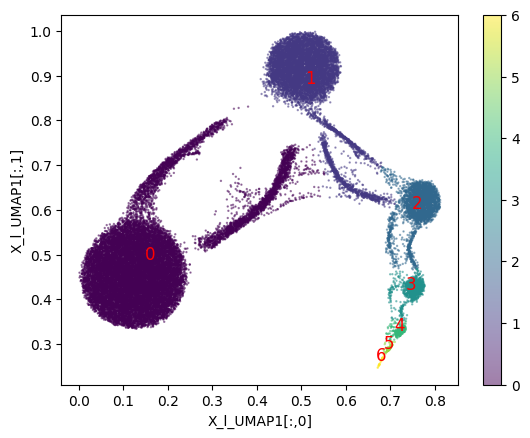

1.6956696697880216

In [ ]:
remapped_classes0 = np.where(
   classes0 <= 1, 0, 
   np.where(classes0 <= 4, 1, 
   np.where(classes0 <= 9, 2, 
   np.where(classes0 <= 12, 3, 
   classes0 - 9)
)))

plot_clusters(X_l_UMAP0, remapped_classes0, SKIP+20)
g2(remapped_classes0)

In [ ]:
X_l_UMAP1 = sklearn_available(data_detect1[:,:50], data_detect1[:,:50], PATH_RESULTS, UMAP, 'detect1[:,:50]_500_2c_Noise_2dB.npy',n_components=2, n_neighbors=500)

In [ ]:
classes1 = assign_labels(X_l_UMAP1, data_detect1[:,:50], SKIP+10, eps=0.0001, min_cluster_size=30)
np.unique(classes1)

/home/jcep-nu/miniconda3/envs/ML/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/jcep-nu/miniconda3/envs/ML/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])

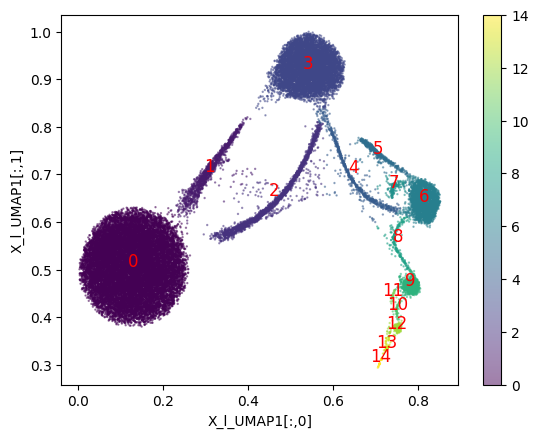

2.428119399657164

In [ ]:
plot_clusters(X_l_UMAP1, classes1, SKIP+20)
g2(classes1)

In [ ]:
data = data_detect1
with plt.style.context("seaborn-v0_8"):
    for i in range(10):
        condition = classes1 == i
        data_ = data[condition]
        plt.figure(figsize=(6,3))
        plt.plot(data_[:,:np.min([data_.shape[0], 1000])], alpha=0.1, linewidth=1)#, c=color[i])
        plt.ylabel(r'$Voltage$ $(a.u.)$')
        plt.xlabel(r'$Time$ $(a.u.)$')
        plt.ylim((-0.01, 0.05))
        plt.savefig(f'src/Noise/ClusterUMAP/cluster{i}.pdf', format='pdf', bbox_inches='tight')
        plt.show()

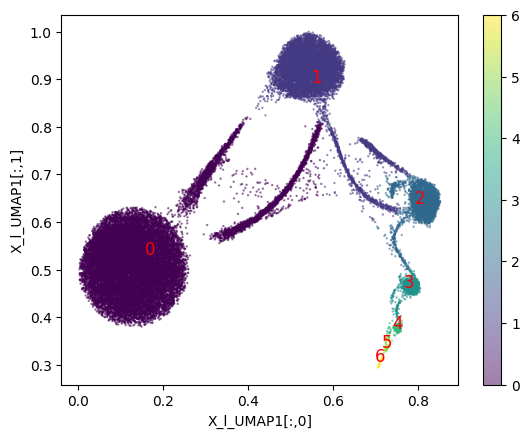

1.6995965500295878

In [ ]:
remapped_classes1 = np.where(
   classes1 <= 2, 0, 
   np.where(classes1 <= 5, 1, 
   np.where(classes1 <= 8, 2, 
   np.where(classes1 <= 11, 3, 
   classes1 - 8)
)))

plot_clusters(X_l_UMAP1, remapped_classes1, SKIP+20)
g2(remapped_classes1)

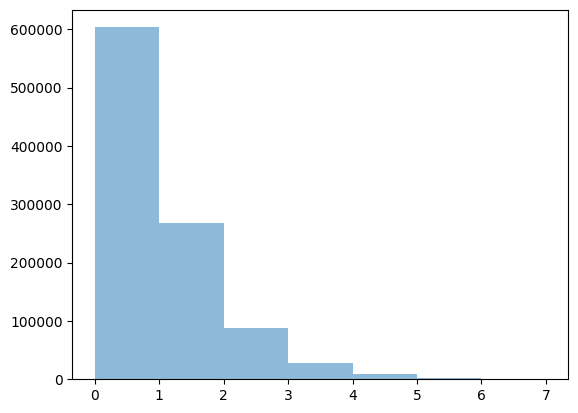

In [ ]:
plt.hist(
   n_detect1,
   bins=np.unique(n_detect1),
   alpha=0.5,
   label='n_detect1'
)
plt.show()

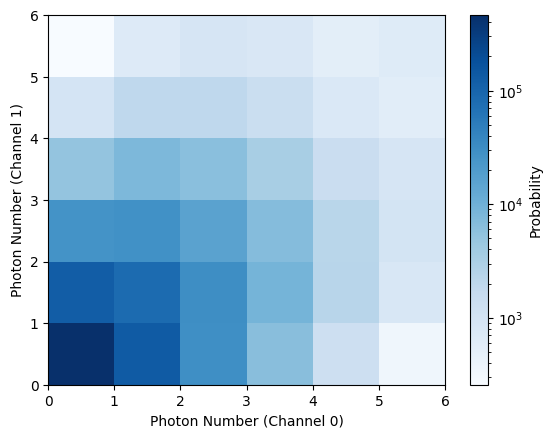

G2 (detector 0) :  1.6956696697880216
G2 (detector 1) :  1.6995965500295878


In [33]:

plt.hist2d(
   remapped_classes0,
   remapped_classes1,
   bins=np.unique(remapped_classes1),
   cmap='Blues',
   cmin=0,
   norm='log'
)
plt.colorbar(label='Probability')
plt.xlabel('Photon Number (Channel 0)')
plt.ylabel('Photon Number (Channel 1)')
plt.savefig('NoiseDist.pdf')
plt.show()

print('G2 (detector 0) : ',g2(remapped_classes0))
print('G2 (detector 1) : ',g2(remapped_classes1))

In [34]:
H_umap2d, xedges, yedges = np.histogram2d(
   remapped_classes0,
   remapped_classes1,
   bins=np.arange(8),
   density=True
)

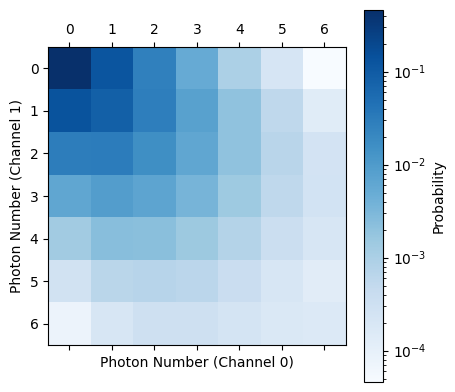

G2 (detector 0) :  1.6956696697880216
G2 (detector 1) :  1.6995965500295878


In [35]:
plt.matshow(H_umap2d, cmap='Blues', norm='log')
plt.colorbar(label='Probability')
plt.xlabel('Photon Number (Channel 0)')
plt.ylabel('Photon Number (Channel 1)')
plt.savefig('NoiseDist.pdf')
plt.show()

print('G2 (detector 0) : ',g2(remapped_classes0))
print('G2 (detector 1) : ',g2(remapped_classes1))

<Figure size 640x480 with 0 Axes>

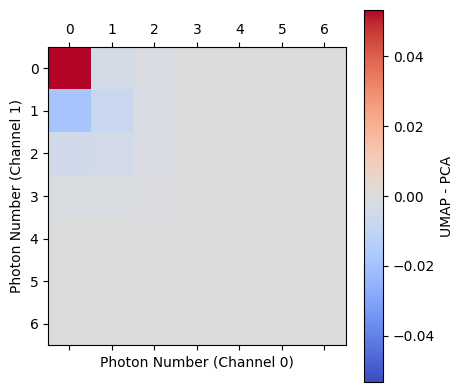

In [36]:
N = 7
H_pca_ = H_pca[:N, :N] / H_pca[:N, :N].sum()
H_umap2d_ = H_umap2d[:N, :N] / H_umap2d[:N, :N].sum()
diff = H_umap2d_ - H_pca_
vlim = np.max(np.abs(diff))

plt.figure()
plt.matshow(diff, cmap='coolwarm', vmin=-vlim, vmax=vlim)
plt.colorbar(label='UMAP - PCA')
plt.xlabel('Photon Number (Channel 0)')
plt.ylabel('Photon Number (Channel 1)')
plt.savefig('UMAP-PCA.pdf')
plt.show()
